In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def obter_climatologia(lat: float, lon: float, start: str = "20210101", end: str = "20251231") -> pd.DataFrame:
    """
    Consulta a API NASA POWER para qualquer coordenada global, limpa falhas (-999),
    agrega a climatologia mensal (12 meses) e calcula janelas sazonais de 3 meses.
    """
    params = "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,GWETROOT"
    url = (
        f"https://power.larc.nasa.gov/api/temporal/daily/point"
        f"?parameters={params}&community=AG&longitude={lon}&latitude={lat}"
        f"&start={start}&end={end}&format=CSV"
    )

    # 1. Leitura pulando as 14 linhas de cabeçalho da NASA
    df = pd.read_csv(url, skiprows=14)

    # 2. Limpeza de nulos (-999 -> NaN) e interpolação de falhas curtas
    df = df.replace(-999, np.nan)
    cols_clima = ['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'GWETROOT']
    df[cols_clima] = df[cols_clima].interpolate(method='linear', limit=3)
    df['PRECTOTCORR'] = df['PRECTOTCORR'].fillna(0)

    # 3. Converter YEAR + DOY em número do mês (1 a 12)
    datas = pd.to_datetime(df['YEAR'].astype(str) + df['DOY'].astype(str).str.zfill(3), format='%Y%j')
    df['MONTH'] = datas.dt.month

    # 4. Passo 1: Diário -> Mensal por Ano
    mensal_anual = df.groupby(['YEAR', 'MONTH']).agg(
        temp_media=('T2M', 'mean'),
        temp_max_mes=('T2M_MAX', 'max'),
        temp_min_mes=('T2M_MIN', 'min'),
        chuva_acumulada_mm=('PRECTOTCORR', 'sum'),
        umidade_ar=('RH2M', 'mean'),
        umidade_solo_raiz=('GWETROOT', 'mean')
    ).reset_index()

    # 5. Passo 2: Climatologia (Perfil histórico de 12 meses)
    clima = mensal_anual.groupby('MONTH').agg(
        temp_media_c=('temp_media', 'mean'),
        temp_min_extrema_c=('temp_min_mes', 'min'),
        temp_max_extrema_c=('temp_max_mes', 'max'),
        chuva_mensal_media_mm=('chuva_acumulada_mm', 'mean'),
        variabilidade_chuva_mm=('chuva_acumulada_mm', 'std'),
        umidade_ar_media=('umidade_ar', 'mean'),
        umidade_solo_raiz=('umidade_solo_raiz', 'mean')
    ).reset_index()

    # 6. Janela Sazonal Móvel de 3 meses (ciclo de safra, com virada Dez->Jan->Fev)
    clima_ciclico = pd.concat([clima, clima.iloc[:2]], ignore_index=True)

    chuva_3m, temp_media_3m, temp_min_3m, temp_max_3m = [], [], [], []
    for i in range(12):
        janela = clima_ciclico.iloc[i:i+3]
        chuva_3m.append(janela['chuva_mensal_media_mm'].sum())
        temp_media_3m.append(janela['temp_media_c'].mean())
        temp_min_3m.append(janela['temp_min_extrema_c'].min())
        temp_max_3m.append(janela['temp_max_extrema_c'].max())

    clima['chuva_safra_3m_mm'] = chuva_3m
    clima['temp_media_safra_3m_c'] = temp_media_3m
    clima['temp_min_safra_3m_c'] = temp_min_3m
    clima['temp_max_safra_3m_c'] = temp_max_3m

    clima.insert(0, 'latitude', lat)
    clima.insert(1, 'longitude', lon)

    return clima.round(2)

In [20]:
regioes = {
    "Petrolina (Brasil - Semiárido)": (-9.3891, -40.5030),
    "Cherkasy (Ucrânia - Temperado)": (49.4444, 31.2357),
    "Niamey (Níger/Sahel - Árido)": (13.5116, 2.1254)
}

resultados = {}

for nome, (lat, lon) in regioes.items():
    print(f"Consultando NASA POWER para: {nome}...")
    df_clima = obter_climatologia(lat, lon)
    resultados[nome] = df_clima

    # Mostra as colunas principais para decisão sazonal
    cols_view = ['MONTH', 'temp_media_c', 'chuva_mensal_media_mm', 'chuva_safra_3m_mm', 'temp_min_safra_3m_c', 'umidade_solo_raiz']
    print(df_clima[cols_view].to_string(index=False))
    print("-" * 75)

Consultando NASA POWER para: Petrolina (Brasil - Semiárido)...
 MONTH  temp_media_c  chuva_mensal_media_mm  chuva_safra_3m_mm  temp_min_safra_3m_c  umidade_solo_raiz
     1         27.97                  69.04             148.53                18.76               0.62
     2         28.26                  46.33             121.92                18.76               0.62
     3         28.66                  33.16              90.18                17.58               0.61
     4         28.13                  42.43              78.52                16.21               0.61
     5         26.56                  14.59              43.79                15.86               0.60
     6         25.20                  21.49              33.99                15.86               0.60
     7         24.67                   7.71              14.85                15.86               0.60
     8         25.39                   4.79              22.46                16.00               0.60
     9    

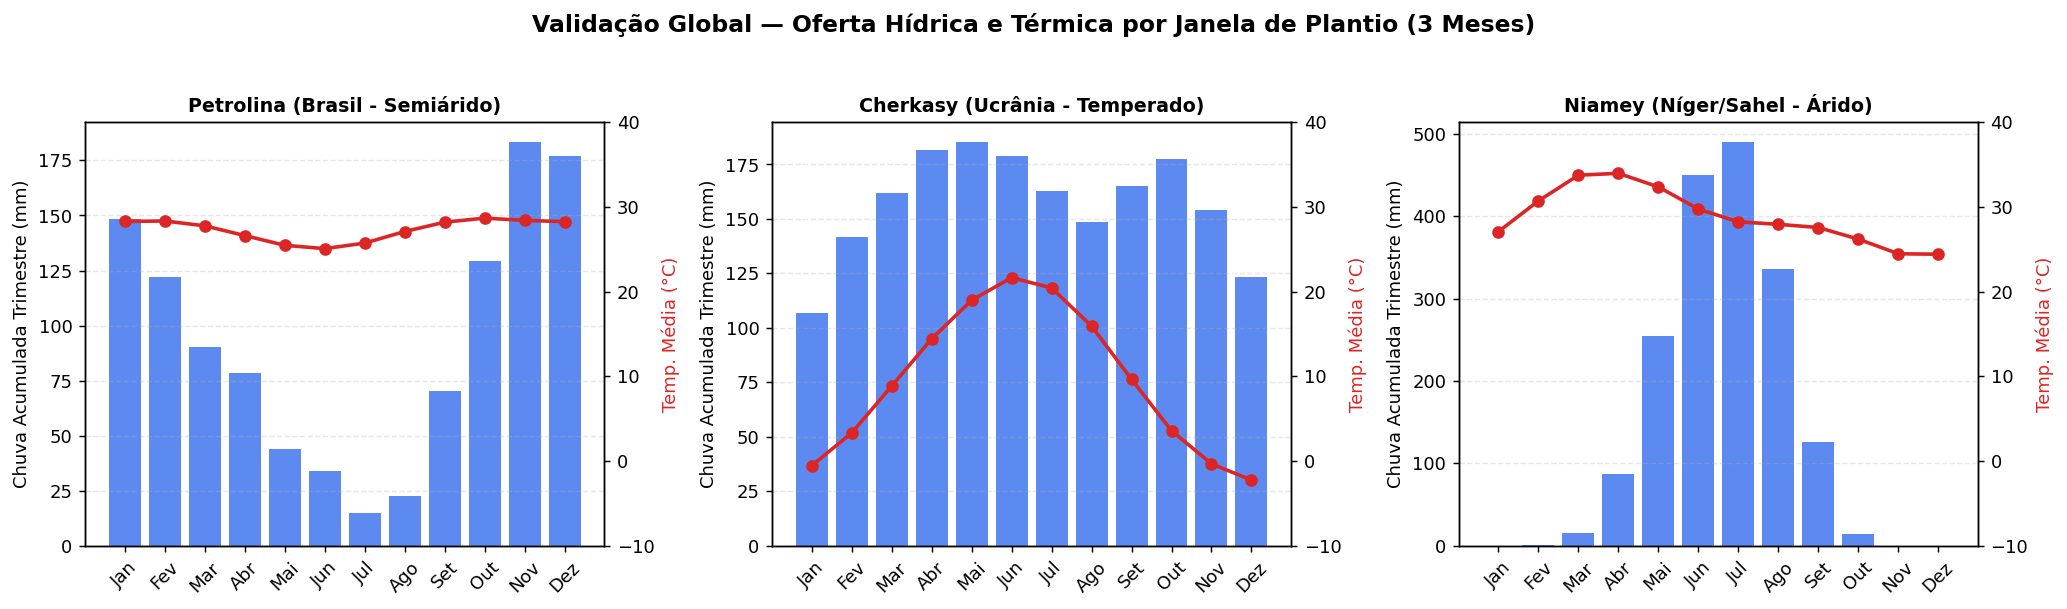

In [21]:
meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=130)

for ax, (nome, df_c) in zip(axes, resultados.items()):
    ax.bar(meses, df_c['chuva_safra_3m_mm'], color='#2563eb', alpha=0.75, label='Chuva Safra 3M (mm)')
    ax.set_title(nome, fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Chuva Acumulada Trimestre (mm)')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

    ax_t = ax.twinx()
    ax_t.plot(meses, df_c['temp_media_safra_3m_c'], color='#dc2626', marker='o', linewidth=2, label='Temp. Média 3M (°C)')
    ax_t.set_ylabel('Temp. Média (°C)', color='#dc2626')
    ax_t.set_ylim(-10, 40)

plt.suptitle('Validação Global — Oferta Hídrica e Térmica por Janela de Plantio (3 Meses)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [22]:
for nome, df_c in resultados.items():
    slug = nome.split(" ")[0].lower()
    arquivo_saida = f"clima_sazonal_{slug}.csv"
    df_c.to_csv(arquivo_saida, index=False)
    print(f"Salvo: {arquivo_saida}")

Salvo: clima_sazonal_petrolina.csv
Salvo: clima_sazonal_cherkasy.csv
Salvo: clima_sazonal_niamey.csv


In [23]:
culturas_data = [
    ("Trigo", "Poaceae", "Cereal", -2.0, 14.0, 23.0, 30.0, 120, 220, 450, 0.35, False, "Alta", 110),
    ("Cevada", "Poaceae", "Cereal", -3.0, 12.0, 21.0, 28.0, 100, 190, 400, 0.30, False, "Media", 95),
    ("Milho", "Poaceae", "Cereal", 8.0, 20.0, 30.0, 38.0, 180, 320, 650, 0.40, False, "Alta", 105),
    ("Arroz", "Poaceae", "Cereal", 12.0, 22.0, 32.0, 40.0, 350, 550, 1000, 0.55, False, "Alta", 120),
    ("Sorgo", "Poaceae", "Cereal", 10.0, 24.0, 34.0, 42.0, 90, 200, 450, 0.25, False, "Media", 100),
    ("Milheto", "Poaceae", "Cereal", 12.0, 26.0, 36.0, 44.0, 65, 150, 350, 0.20, False, "Baixa", 85),
    ("Soja", "Fabaceae", "Leguminosa", 8.0, 20.0, 30.0, 38.0, 180, 300, 600, 0.38, True, "Baixa", 110),
    ("Feijao-Caupi", "Fabaceae", "Leguminosa", 10.0, 22.0, 33.0, 40.0, 85, 180, 420, 0.25, True, "Baixa", 75),
    ("Feijao-Comum", "Fabaceae", "Leguminosa", 6.0, 16.0, 25.0, 32.0, 140, 250, 500, 0.35, True, "Baixa", 85),
    ("Amendoim", "Fabaceae", "Leguminosa", 10.0, 22.0, 32.0, 40.0, 110, 220, 480, 0.28, True, "Baixa", 105),
    ("Grao-de-Bico", "Fabaceae", "Leguminosa", 0.0, 15.0, 25.0, 33.0, 95, 180, 380, 0.28, True, "Baixa", 100),
    ("Mandioca", "Euphorbiaceae", "Raiz/Tuberculo", 10.0, 22.0, 32.0, 40.0, 100, 250, 600, 0.25, False, "Baixa", 240),
    ("Batata-Inglesa", "Solanaceae", "Raiz/Tuberculo", 1.0, 14.0, 22.0, 29.0, 150, 260, 500, 0.40, False, "Alta", 100),
    ("Girassol", "Asteraceae", "Oleaginosa", 4.0, 18.0, 28.0, 36.0, 110, 210, 450, 0.30, False, "Media", 95),
    ("Algodao", "Malvaceae", "Fibra/Oleaginosa", 11.0, 23.0, 33.0, 41.0, 150, 280, 550, 0.32, False, "Alta", 140)
]

colunas = [
    "cultura", "familia_botanica", "grupo",
    "temp_min_tol_c", "temp_ideal_min_c", "temp_ideal_max_c", "temp_max_tol_c",
    "chuva_min_3m_mm", "chuva_ideal_3m_mm", "chuva_max_3m_mm",
    "umidade_solo_min", "fixa_nitrogenio", "demanda_nitrogenio", "ciclo_dias"
]

df_culturas = pd.DataFrame(culturas_data, columns=colunas)
df_culturas.to_csv("matriz_culturas_fao.csv", index=False)
print("Matriz de 15 culturas salva com sucesso!")
df_culturas[["cultura", "familia_botanica", "temp_ideal_min_c", "temp_ideal_max_c", "chuva_min_3m_mm", "chuva_ideal_3m_mm", "fixa_nitrogenio"]]

Matriz de 15 culturas salva com sucesso!


,cultura,familia_botanica,temp_ideal_min_c,temp_ideal_max_c,chuva_min_3m_mm,chuva_ideal_3m_mm,fixa_nitrogenio
0,Trigo,Poaceae,14.0,23.0,120,220,False
1,Cevada,Poaceae,12.0,21.0,100,190,False
2,Milho,Poaceae,20.0,30.0,180,320,False
3,Arroz,Poaceae,22.0,32.0,350,550,False
4,Sorgo,Poaceae,24.0,34.0,90,200,False
5,Milheto,Poaceae,26.0,36.0,65,150,False
6,Soja,Fabaceae,20.0,30.0,180,300,True
7,Feijao-Caupi,Fabaceae,22.0,33.0,85,180,True
8,Feijao-Comum,Fabaceae,16.0,25.0,140,250,True
9,Amendoim,Fabaceae,22.0,32.0,110,220,True


In [24]:
def recomendar_culturas(df_clima: pd.DataFrame, mes_plantio: int, df_culturas: pd.DataFrame, cultura_anterior: str = None) -> pd.DataFrame:
    """
    Filtra culturas viáveis para o mês escolhido e ranqueia por aptidão climática e rotação de solo.
    """
    linha_mes = df_clima[df_clima['MONTH'] == mes_plantio].iloc[0]

    t_med = linha_mes['temp_media_safra_3m_c']
    t_min = linha_mes['temp_min_safra_3m_c']
    chuva = linha_mes['chuva_safra_3m_mm']

    # 1. Filtros biofísicos absolutos (Risco de geada via t_min + Faixa térmica e hídrica da safra)
    viaveis = df_culturas[
        (t_min >= df_culturas['temp_min_tol_c']) &
        (t_med >= df_culturas['temp_ideal_min_c'] - 2.0) &
        (t_med <= df_culturas['temp_ideal_max_c'] + 2.0) &
        (chuva >= df_culturas['chuva_min_3m_mm']) &
        (chuva <= df_culturas['chuva_max_3m_mm'])
    ].copy()

    if viaveis.empty:
        return pd.DataFrame(columns=['cultura', 'grupo', 'score_aptidao', 'justificativa'])

    # 2. Score Térmico (até 40 pontos)
    centro_temp = (viaveis['temp_ideal_min_c'] + viaveis['temp_ideal_max_c']) / 2
    largura_temp = (viaveis['temp_ideal_max_c'] - viaveis['temp_ideal_min_c']) / 2
    score_temp = 40 * np.clip(1 - np.abs(t_med - centro_temp) / (largura_temp + 3), 0, 1)

    # 3. Score Hídrico (até 40 pontos)
    score_agua = 40 * np.clip(1 - np.abs(chuva - viaveis['chuva_ideal_3m_mm']) / viaveis['chuva_ideal_3m_mm'], 0, 1)

    # 4. Score de Rotação de Solo (até 20 pontos)
    score_rotacao = pd.Series(10.0, index=viaveis.index)
    justificativas = []

    info_ant = None
    if cultura_anterior and cultura_anterior in df_culturas['cultura'].values:
        info_ant = df_culturas[df_culturas['cultura'] == cultura_anterior].iloc[0]
        score_rotacao = np.where(viaveis['familia_botanica'] == info_ant['familia_botanica'], 0.0, 12.0)
        if info_ant['demanda_nitrogenio'] == 'Alta':
            score_rotacao = np.where(viaveis['fixa_nitrogenio'], score_rotacao + 8.0, score_rotacao)

    viaveis['score_aptidao'] = (score_temp + score_agua + score_rotacao).round(1)

    # Gera explicação automática para mostrar na tela do aplicativo
    for _, row in viaveis.iterrows():
        motivos = [f"Clima ideal ({t_med:.1f}°C, {chuva:.0f}mm/3m)"]
        if info_ant is not None:
            if row['familia_botanica'] == info_ant['familia_botanica']:
                motivos.append(f"Alerta: mesma família ({row['familia_botanica']}) de {cultura_anterior}")
            elif info_ant['demanda_nitrogenio'] == 'Alta' and row['fixa_nitrogenio']:
                motivos.append(f"Recupera nitrogênio após {cultura_anterior}")
            else:
                motivos.append(f"Boa quebra de ciclo após {cultura_anterior}")
        justificativas.append(" | ".join(motivos))

    viaveis['justificativa'] = justificativas
    return viaveis.sort_values('score_aptidao', ascending=False)[['cultura', 'grupo', 'fixa_nitrogenio', 'score_aptidao', 'justificativa']]

# --- TESTE NAS 3 REGIÕES ---
print("1. SEMIÁRIDO (Petrolina) - Plantio em Fevereiro após Milho:")
print(recomendar_culturas(resultados["Petrolina (Brasil - Semiárido)"], 2, df_culturas, "Milho").head(5).to_string(index=False))

print("\n2. TEMPERADO (Ucrânia) - Plantio em Maio após Milho:")
print(recomendar_culturas(resultados["Cherkasy (Ucrânia - Temperado)"], 5, df_culturas, "Milho").head(5).to_string(index=False))

print("\n3. ÁRIDO (Sahel/África) - Plantio em Julho após Sorgo:")
print(recomendar_culturas(resultados["Niamey (Níger/Sahel - Árido)"], 7, df_culturas, "Sorgo").head(5).to_string(index=False))

1. SEMIÁRIDO (Petrolina) - Plantio em Fevereiro após Milho:
     cultura          grupo  fixa_nitrogenio  score_aptidao                                                             justificativa
Feijao-Caupi     Leguminosa             True           83.1           Clima ideal (28.4°C, 122mm/3m) | Recupera nitrogênio após Milho
    Amendoim     Leguminosa             True           75.4           Clima ideal (28.4°C, 122mm/3m) | Recupera nitrogênio após Milho
    Mandioca Raiz/Tuberculo            False           64.8           Clima ideal (28.4°C, 122mm/3m) | Boa quebra de ciclo após Milho
       Sorgo         Cereal            False           61.1 Clima ideal (28.4°C, 122mm/3m) | Alerta: mesma família (Poaceae) de Milho
     Milheto         Cereal            False           59.3 Clima ideal (28.4°C, 122mm/3m) | Alerta: mesma família (Poaceae) de Milho

2. TEMPERADO (Ucrânia) - Plantio em Maio após Milho:
       cultura          grupo  fixa_nitrogenio  score_aptidao                     

In [25]:
NOMES_MESES = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro"
}

def descobrir_melhor_epoca_plantio(
    df_clima: pd.DataFrame,
    df_culturas: pd.DataFrame,
    cultura_desejada: str = None,
    cultura_anterior: str = None
) -> pd.DataFrame:
    """
    Varre os 12 meses do ano para descobrir a melhor janela de plantio:
    - Se `cultura_desejada` for informada: ranqueia os melhores meses para plantar essa cultura.
    - Se `cultura_desejada` for None: identifica a cultura campeã e o total de opções viáveis em cada mês.
    """
    registros = []

    for mes in range(1, 13):
        rec_mes = recomendar_culturas(df_clima, mes, df_culturas, cultura_anterior)
        linha_clima = df_clima[df_clima['MONTH'] == mes].iloc[0]

        if cultura_desejada:
            filtro = rec_mes[rec_mes['cultura'].str.lower() == cultura_desejada.lower()]
            if not filtro.empty:
                item = filtro.iloc[0]
                registros.append({
                    'mes_num': mes,
                    'mes': NOMES_MESES[mes],
                    'cultura_alvo': item['cultura'],
                    'status': 'Viável',
                    'score_aptidao': item['score_aptidao'],
                    'temp_safra_c': linha_clima['temp_media_safra_3m_c'],
                    'chuva_safra_mm': linha_clima['chuva_safra_3m_mm'],
                    'justificativa': item['justificativa']
                })
            else:
                registros.append({
                    'mes_num': mes,
                    'mes': NOMES_MESES[mes],
                    'cultura_alvo': cultura_desejada,
                    'status': 'Inviável (Risco Térmico/Hídrico)',
                    'score_aptidao': 0.0,
                    'temp_safra_c': linha_clima['temp_media_safra_3m_c'],
                    'chuva_safra_mm': linha_clima['chuva_safra_3m_mm'],
                    'justificativa': f"Fora dos limiares (Mín: {linha_clima['temp_min_safra_3m_c']}°C, Chuva: {linha_clima['chuva_safra_3m_mm']}mm)"
                })
        else:
            if not rec_mes.empty:
                campea = rec_mes.iloc[0]
                top3 = ", ".join(rec_mes['cultura'].head(3).tolist())
                registros.append({
                    'mes_num': mes,
                    'mes': NOMES_MESES[mes],
                    'melhor_cultura': campea['cultura'],
                    'score_maximo': campea['score_aptidao'],
                    'qtd_opcoes_viaveis': len(rec_mes),
                    'top_3_culturas': top3,
                    'justificativa_campea': campea['justificativa']
                })
            else:
                registros.append({
                    'mes_num': mes,
                    'mes': NOMES_MESES[mes],
                    'melhor_cultura': 'Nenhuma (Pousio / Estufa)',
                    'score_maximo': 0.0,
                    'qtd_opcoes_viaveis': 0,
                    'top_3_culturas': '-',
                    'justificativa_campea': f"Risco severo (Mín: {linha_clima['temp_min_safra_3m_c']}°C)"
                })

    df_anual = pd.DataFrame(registros)
    col_ord = 'score_aptidao' if cultura_desejada else 'score_maximo'
    return df_anual.sort_values(by=[col_ord, 'mes_num'], ascending=[False, True]).reset_index(drop=True)

# --- TESTES DE VALIDAÇÃO ---
print("=== MODO 1: Melhor época geral (Ucrânia, após safra de Milho) ===")
df_calendario_ucrania = descobrir_melhor_epoca_plantio(
    resultados["Cherkasy (Ucrânia - Temperado)"],
    df_culturas,
    cultura_anterior="Milho"
)
print(df_calendario_ucrania[['mes', 'melhor_cultura', 'score_maximo', 'qtd_opcoes_viaveis', 'top_3_culturas']].to_string(index=False))

print("\n=== MODO 2: Melhor época específica para Trigo (Ucrânia, após Soja) ===")
df_epoca_trigo = descobrir_melhor_epoca_plantio(
    resultados["Cherkasy (Ucrânia - Temperado)"],
    df_culturas,
    cultura_desejada="Trigo",
    cultura_anterior="Soja"
)
print(df_epoca_trigo[['mes', 'status', 'score_aptidao', 'temp_safra_c', 'chuva_safra_mm']].head(5).to_string(index=False))

=== MODO 1: Melhor época geral (Ucrânia, após safra de Milho) ===
      mes            melhor_cultura  score_maximo  qtd_opcoes_viaveis                         top_3_culturas
    Julho              Grao-de-Bico          93.9                   4    Grao-de-Bico, Batata-Inglesa, Trigo
     Maio              Grao-de-Bico          93.8                   4    Grao-de-Bico, Batata-Inglesa, Trigo
    Junho              Grao-de-Bico          91.5                   5 Grao-de-Bico, Girassol, Batata-Inglesa
   Agosto                    Cevada          68.3                   1                                 Cevada
  Janeiro Nenhuma (Pousio / Estufa)           0.0                   0                                      -
Fevereiro Nenhuma (Pousio / Estufa)           0.0                   0                                      -
    Março Nenhuma (Pousio / Estufa)           0.0                   0                                      -
    Abril Nenhuma (Pousio / Estufa)           0.0             

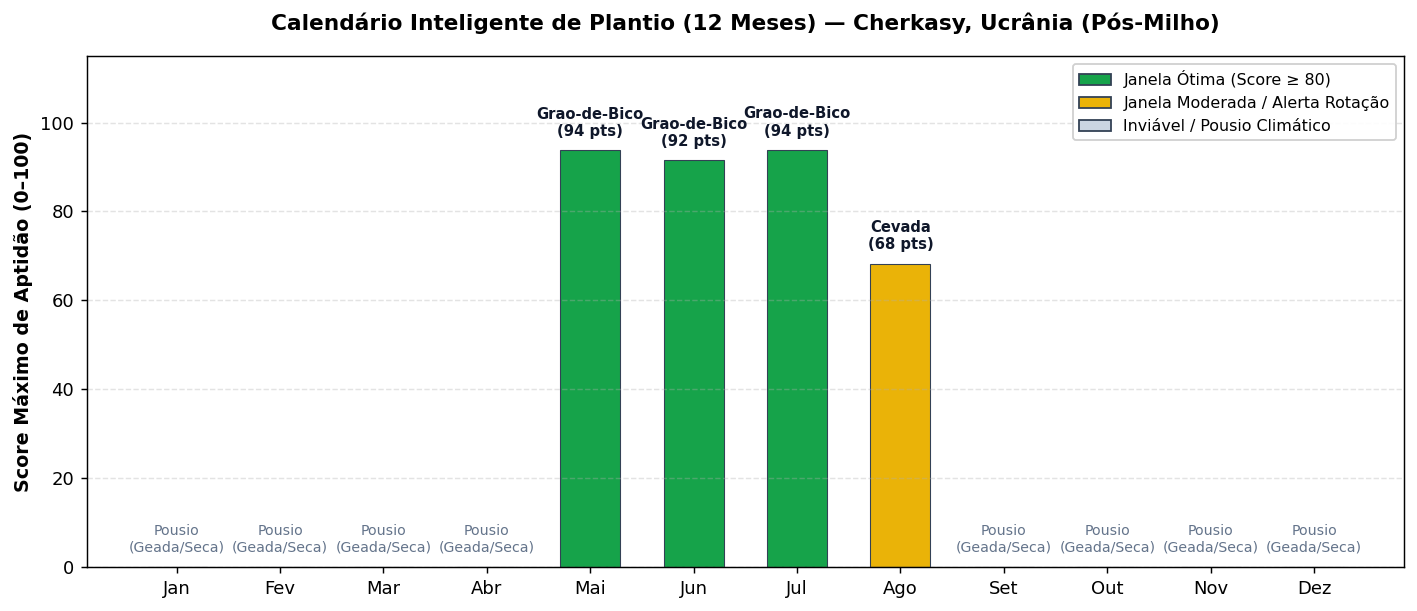

In [26]:
from matplotlib.patches import Patch

def plotar_calendario_anual(df_calendario: pd.DataFrame, titulo_local: str):
    df_plot = df_calendario.sort_values('mes_num').reset_index(drop=True)
    meses_curtos = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

    fig, ax = plt.subplots(figsize=(11, 4.8), dpi=130)
    cores = ['#16a34a' if s >= 80 else ('#eab308' if s > 0 else '#cbd5e1') for s in df_plot['score_maximo']]
    bars = ax.bar(meses_curtos, df_plot['score_maximo'], color=cores, width=0.58, edgecolor='#334155', linewidth=0.6)

    ax.set_ylim(0, 115)
    ax.set_ylabel('Score Máximo de Aptidão (0–100)', fontsize=10.5, fontweight='bold')
    ax.set_title(f'Calendário Inteligente de Plantio (12 Meses) — {titulo_local}', fontsize=12, fontweight='bold', pad=14)
    ax.grid(axis='y', linestyle='--', alpha=0.35)

    for bar, (_, row) in zip(bars, df_plot.iterrows()):
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 2.5, f"{row['melhor_cultura']}\n({h:.0f} pts)",
                    ha='center', va='bottom', fontsize=8.2, fontweight='bold', color='#0f172a')
        else:
            ax.text(bar.get_x() + bar.get_width()/2, 3.0, "Pousio\n(Geada/Seca)",
                    ha='center', va='bottom', fontsize=7.8, color='#64748b')

    legenda = [
        Patch(facecolor='#16a34a', edgecolor='#334155', label='Janela Ótima (Score ≥ 80)'),
        Patch(facecolor='#eab308', edgecolor='#334155', label='Janela Moderada / Alerta Rotação'),
        Patch(facecolor='#cbd5e1', edgecolor='#334155', label='Inviável / Pousio Climático')
    ]
    ax.legend(handles=legenda, loc='upper right', frameon=True, facecolor='white', framealpha=0.92, fontsize=8.8)
    plt.tight_layout()
    plt.show()

# Gera o gráfico para qualquer uma das 3 regiões
plotar_calendario_anual(df_calendario_ucrania, "Cherkasy, Ucrânia (Pós-Milho)")

In [27]:
import pandas as pd
import json

# ==========================================
# 1. MATRIZ AGRONÔMICA (Frente 2 - Ciência de Dados)
# ==========================================
dados_culturas = [
    {"cultura": "Feijão Macassar", "exigencia_hidrica": "Média", "fixa_nitrogenio": True, "profundidade_raiz": "Rasa", "ciclo_dias": 75},
    {"cultura": "Mandioca", "exigencia_hidrica": "Baixa", "fixa_nitrogenio": False, "profundidade_raiz": "Profunda", "ciclo_dias": 240},
    {"cultura": "Milho", "exigencia_hidrica": "Alta", "fixa_nitrogenio": False, "profundidade_raiz": "Rasa", "ciclo_dias": 120},
    {"cultura": "Palma Forrageira", "exigencia_hidrica": "Baixa", "fixa_nitrogenio": False, "profundidade_raiz": "Rasa", "ciclo_dias": 365}
]
df_culturas = pd.DataFrame(dados_culturas)

# ==========================================
# 2. MOTOR DE DECISÃO & LEITURA CLIMÁTICA
# ==========================================
def gerar_recomendacao_mvp(caminho_arquivo, cultura_anterior):
    # Lê o arquivo limpo (sem o skiprows=14)
    df_clima = pd.read_csv(caminho_arquivo)

    # Médias climáticas da base
    temp_min_historica = df_clima['T2M_MIN'].mean()
    chuva_media_diaria = df_clima['PRECTOTCORR'].mean()

    # Classificação do clima
    risco_geada = "Nulo" if temp_min_historica > 5 else "Alto"
    previsao_chuva = "Baixa" if chuva_media_diaria < 2 else ("Média" if chuva_media_diaria < 5 else "Alta")

    df_rank = df_culturas.copy()
    df_rank['score'] = 50
    df_rank['justificativa'] = ""

    for idx, row in df_rank.iterrows():
        justificativas = []

        # Filtro 1: Resiliência Hídrica
        if previsao_chuva == "Baixa" and row['exigencia_hidrica'] == "Baixa":
            df_rank.at[idx, 'score'] += 30
            justificativas.append("Tolera a baixa umidade prevista pelos dados da NASA")
        elif previsao_chuva == "Baixa" and row['exigencia_hidrica'] == "Alta":
            df_rank.at[idx, 'score'] -= 40
            justificativas.append("Alto risco de quebra de safra por déficit hídrico")

        # Filtro 2: Rotação de Culturas e Solo
        if cultura_anterior == "Milho":
            if row['fixa_nitrogenio']:
                df_rank.at[idx, 'score'] += 25
                justificativas.append("Fixa nitrogênio (recupera solo esgotado pelo Milho)")
            if row['profundidade_raiz'] == "Profunda":
                df_rank.at[idx, 'score'] += 15
                justificativas.append("Sistema radicular profundo acessa nutrientes intocados pelo Milho")

        df_rank.at[idx, 'justificativa'] = " e ".join(justificativas) if justificativas else "Apta para plantio regular"

    df_rank = df_rank.sort_values(by='score', ascending=False).reset_index(drop=True)
    melhor_opcao = df_rank.iloc[0]

    payload_frontend = {
        "cultura_sugerida": melhor_opcao['cultura'],
        "risco_geada": risco_geada,
        "justificativa": melhor_opcao['justificativa']
    }

    return json.dumps(payload_frontend, indent=2, ensure_ascii=False)

# ==========================================
# 3. TESTE DA API
# ==========================================
# Apontando para o arquivo que já está na sua pasta
arquivo_petrolina = "clima_sazonal_petrolina.csv"

json_para_o_app = gerar_recomendacao_mvp(arquivo_petrolina, cultura_anterior="Milho")
print(json_para_o_app)

{
  "cultura_sugerida": "Mandioca",
  "risco_geada": "Nulo",
  "justificativa": "Tolera a baixa umidade prevista pelos dados da NASA e Sistema radicular profundo acessa nutrientes intocados pelo Milho"
}
